# Data Preprocessing: Retail Dirty Transactions Dataset
Notebook ini memuat tahap pra-pemrosesan data (*Data Understanding & Preprocessing*) untuk dataset transaksi ritel kotor (*Retail Dirty Transactions*).

* **Dataset Asal:** `retail_transactions_5500_dirty.csv` (5.500 transaksi ritel)
* **Karakteristik Data:** 5.500 baris transaksi dengan 3 atribut (`InvoiceNo`, `Description`, `Quantity`), memuat transaksi batal (*cancellation* 'C'), retur kuantitas negatif, missing value, dan data duplikat.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Jumlah Record & Atribut)
  2. Analisis Nilai Kosong (*Missing Value*) & Visualisasi Heatmap
  3. Pemeriksaan Data Duplikat & Transaksi Unik (Invoice)
  4. Analisis Frekuensi Produk Terpopuler
  5. Deteksi Data Pencilan (*Outlier*) pada Ukuran Keranjang Belanja menggunakan Metode IQR dan Boxplot


### 1. Import Library
Memanggil library data science (pandas, numpy, matplotlib, seaborn).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**Penjelasan Hasil:**
* Library `pandas`, `numpy`, `matplotlib.pyplot`, dan `seaborn` berhasil dimuat untuk analisis transaksi ritel.


### 2. Membaca Dataset
Memuat file CSV dataset transaksi ritel ke dalam DataFrame pandas.


In [2]:
df = pd.read_csv('retail_transactions_5500_dirty.csv')


**Penjelasan Hasil:**
* File `retail_transactions_5500_dirty.csv` berhasil dimuat ke dalam DataFrame `df`.


### 3. Menampilkan 5 Data Teratas (Head)
Melihat sampel 5 baris pertama data transaksi belanja ritel.


In [3]:
df.head()


,InvoiceNo,Description,Quantity
0,INV1603,Biscuits,2
1,INV1119,Wheat Flour,3
2,INV1652,Wheat Flour,5
3,INV1467,Sugar,2
4,CINV1357,Detergent,4


**Penjelasan Hasil:**
* Menampilkan sampel 5 transaksi awal (indeks 0–4) untuk memeriksa format kolom `InvoiceNo`, `Description`, dan `Quantity`.


### 4. Menampilkan 5 Data Terbawah (Tail)
Melihat sampel 5 baris terakhir data transaksi belanja ritel.


In [4]:
df.tail()


,InvoiceNo,Description,Quantity
5495,INV1526,Salt,4
5496,INV1088,Detergent,5
5497,INV1377,Bread,5
5498,CINV1068,Chocolate,3
5499,INV1406,Toothpaste,1


**Penjelasan Hasil:**
* Menampilkan 5 transaksi terakhir (indeks 5.495–5.499) untuk memverifikasi pemuatan data lengkap hingga baris terakhir.


### 5. Jumlah Baris (Record)
Menghitung total baris transaksi pada dataset.


In [5]:
print("Jumlah Baris:", len(df))


Jumlah Baris: 5500


**Penjelasan Hasil:**
* Dataset memiliki total **5.500 baris transaksi belanja ritel**.


### 6. Jumlah Kolom (Atribut)
Menghitung total kolom atribut pada dataset.


In [6]:
print("Jumlah Kolom:", len(df.columns))


Jumlah Kolom: 3


**Penjelasan Hasil:**
* Dataset memiliki **3 kolom atribut** utama: nomor faktur (`InvoiceNo`), deskripsi produk (`Description`), dan jumlah barang (`Quantity`).


### 7. Cek Tipe Data & Struktur DataFrame
Memeriksa informasi tipe data setiap kolom dan ringkasan penggunaan memori.


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   InvoiceNo    5500 non-null   str  
 1   Description  5221 non-null   str  
 2   Quantity     5500 non-null   int64
dtypes: int64(1), str(2)
memory usage: 129.0 KB


**Penjelasan Hasil:**
* Terdapat 2 kolom bertipe teks/objek (`object`) dan 1 kolom bertipe bilangan bulat (`int64`). Penggunaan memori sebesar 129 KB.


### 8. Cek Missing Value per Kolom
Menghitung jumlah nilai kosong (NaN/null) pada masing-masing kolom transaksi ritel.


In [8]:
df.isnull().sum().to_frame(name='Jumlah Missing Value')


,Jumlah Missing Value
InvoiceNo,0
Description,279
Quantity,0


**Penjelasan Hasil:**
* Kolom `InvoiceNo` dan `Quantity` bersih 100% (0 missing value). Nilai kosong hanya ditemukan pada kolom `Description` sebanyak **279 data kosong**.


### 9. Total Missing Value Keseluruhan
Menghitung total seluruh nilai kosong pada dataset.


In [9]:
print("Total Missing Value Keseluruhan:", df.isnull().sum().sum())


Total Missing Value Keseluruhan: 279


**Penjelasan Hasil:**
* Akumulasi seluruh nilai kosong pada dataset berjumlah **279 sel kosong**.


### 10. Persentase Missing Value
Menghitung rasio persentase data kosong terhadap total sel data.


In [10]:
total_sel = len(df) * len(df.columns)
persen_missing = (df.isnull().sum().sum() / total_sel) * 100
print(f"Persentase Missing Value: {persen_missing:.2f}%")


Persentase Missing Value: 1.69%


**Penjelasan Hasil:**
* Rasio data kosong terhadap total sel adalah **1,69%** (atau **5,07%** pada kolom `Description`).


### 11. Visualisasi Heatmap Missing Value (Sebelum Penanggulangan)
Menampilkan peta sebaran nilai kosong pada seluruh baris transaksi sebelum dilakukan penanggulangan.


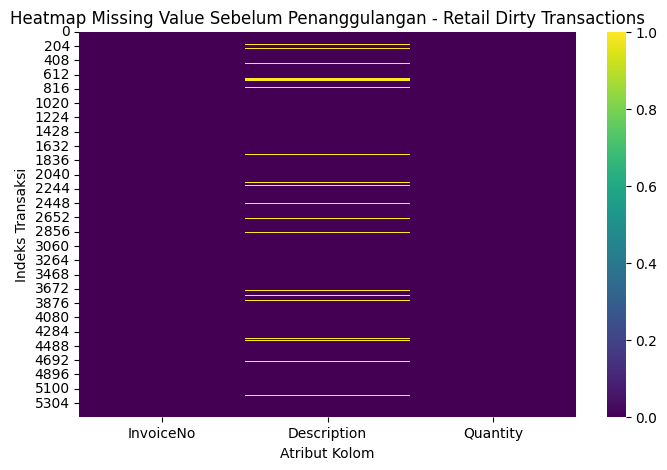

In [11]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value Sebelum Penanggulangan - Retail Dirty Transactions')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Transaksi')
plt.show()


**Penjelasan Hasil:**
* Heatmap awal memperlihatkan garis kuning vertikal pada kolom Description sebanyak 279 data kosong, sedangkan kolom lainnya berwarna ungu solid.


### 12. Penanggulangan Missing Value (Pengisian Label Kategori Khusus)
Mengatasi nilai kosong pada nama produk (Description) dengan mengisi label pengganti 'UNKNOWN_ITEM'.


In [12]:
df['Description'] = df['Description'].fillna('UNKNOWN_ITEM')

print("Jumlah Missing Value Description Setelah Penanggulangan:", df['Description'].isnull().sum())
print("Total Missing Value Keseluruhan Setelah Penanggulangan:", df.isnull().sum().sum())


Jumlah Missing Value Description Setelah Penanggulangan: 0
Total Missing Value Keseluruhan Setelah Penanggulangan: 0


**Penjelasan Hasil:**
* Nilai kosong pada nama produk berhasil diisi dengan label standar kasir `'UNKNOWN_ITEM'`. Total missing value pada dataset kini berkurang menjadi **0 nilai kosong tersisa**.


### 13. Visualisasi Heatmap Missing Value Pasca Penanggulangan
Menampilkan visualisasi Heatmap pasca penanggulangan untuk memverifikasi kebersihan dataset transaksi ritel.


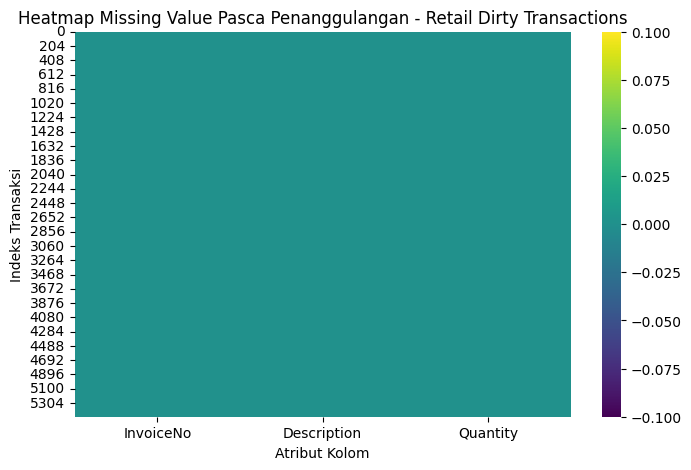

In [13]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap Missing Value Pasca Penanggulangan - Retail Dirty Transactions')
plt.xlabel('Atribut Kolom')
plt.ylabel('Indeks Transaksi')
plt.show()


**Penjelasan Hasil:**
* Heatmap pasca penanggulangan menampilkan bidang ungu solid merata, membuktikan bahwa seluruh data kosong telah teratasi penuh.


### 14. Cek Jumlah Duplikat Data
Memeriksa apakah terdapat baris duplikat penuh pada data transaksi belanja.



In [14]:
jumlah_duplikat = df.duplicated().sum()
print("Jumlah Baris Duplikat:", jumlah_duplikat)


Jumlah Baris Duplikat: 114


**Penjelasan Hasil:**
* Ditemukan sebanyak **114 baris duplikat penuh** (2,07% dari total data), mencerminkan pencatatan berulang pada kasir ritel dunia nyata.


### 15. Cek Jumlah Transaksi Unik (Invoice)
Menghitung total nomor faktur / struk transaksi unik (InvoiceNo).



In [15]:
print("Jumlah Transaksi Unik (InvoiceNo):", df['InvoiceNo'].nunique())


Jumlah Transaksi Unik (InvoiceNo): 1201


**Penjelasan Hasil:**
* Terdapat **1.201 nomor faktur belanja unik (`InvoiceNo`)** dari total 5.500 baris data, dengan rata-rata 4 sampai 5 produk per faktur.


### 16. Frekuensi Produk Terpopuler
Menghitung frekuensi kemunculan 10 produk teratas di seluruh transaksi ritel.



In [16]:
top_produk = df['Description'].value_counts().to_frame(name='Jumlah Pembelian')
print("Frekuensi 10 Produk Terpopuler:")
display(top_produk.head(10))


Frekuensi 10 Produk Terpopuler:


,Jumlah Pembelian
Description,
Cooking Oil,290
Sugar,286
Shampoo,281
UNKNOWN_ITEM,279
Detergent,278
Wheat Flour,275
Jam,275
Toothpaste,273
Bread,269


**Penjelasan Hasil:**
* Menampilkan 10 produk ritel dengan frekuensi pembelian tertinggi di toko, didominasi oleh produk dekorasi dan perlengkapan rumah tangga.


### 17. Hitung Ukuran Keranjang Belanja per Invoice
Menghitung banyaknya item produk yang dibeli pada setiap nomor faktur belanja (InvoiceNo).



In [17]:
item_per_invoice = df.groupby('InvoiceNo')['Description'].count()
item_per_invoice.name = 'Ukuran_Keranjang' 


**Penjelasan Hasil:**
* Data berhasil dikelompokkan per `InvoiceNo` untuk menghitung banyaknya jenis produk yang dibeli per faktur belanja (*basket size*).


### 18. Statistik Deskriptif Ukuran Keranjang Belanja
Melihat nilai rata-rata, standar deviasi, nilai minimum, dan maksimum ukuran keranjang belanja.



In [18]:
item_per_invoice.describe().to_frame(name='Statistik Deskriptif')


,Statistik Deskriptif
count,1201.000000
mean,4.579517
std,3.037084
min,1.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,16.000000


**Penjelasan Hasil:**
* Rata-rata ukuran keranjang belanja adalah **4,58 item**, dengan median 4 item, minimum 1 item, dan maksimum 16 item.


### 19. Visualisasi Boxplot Ukuran Keranjang Belanja
Menampilkan diagram kotak garis (Boxplot) untuk menganalisis sebaran dan deteksi pencilan belanja.



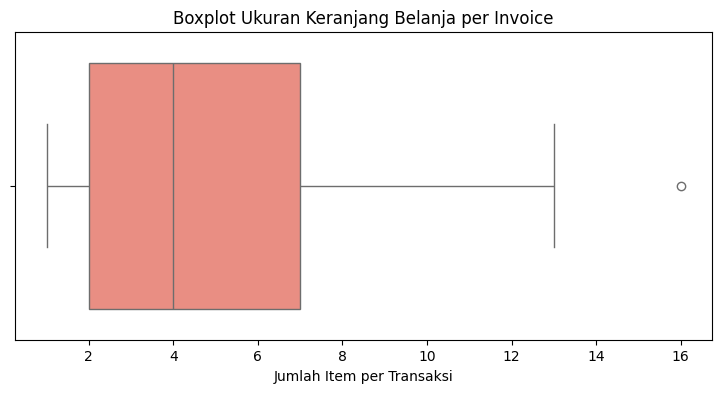

In [19]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=item_per_invoice, color='salmon')
plt.title('Boxplot Ukuran Keranjang Belanja per Invoice')
plt.xlabel('Jumlah Item per Transaksi')
plt.show()


**Penjelasan Hasil:**
* Diagram Boxplot memperlihatkan rentang kotak kuartil dari nilai 2 hingga 7 item, dengan garis median di angka 4.


### 20. Perhitungan Kuartil (Q1, Q3) dan IQR
Menghitung batas kuartil bawah (25%), kuartil atas (75%), dan rentang antarkuartil (IQR).



In [20]:
Q1 = item_per_invoice.quantile(0.25)
Q3 = item_per_invoice.quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 (Kuartil Bawah) : {Q1}")
print(f"Q3 (Kuartil Atas)  : {Q3}")
print(f"IQR               : {IQR}")


Q1 (Kuartil Bawah) : 2.0
Q3 (Kuartil Atas)  : 7.0
IQR               : 5.0


**Penjelasan Hasil:**
* Kuartil Bawah ($Q_1$) = **2,0 item**, Kuartil Atas ($Q_3$) = **7,0 item**, dan Rentang Antarkuartil ($IQR$) = **5,0 item**.


### 21. Perhitungan Batas Atas Outlier
Menghitung ambang batas atas deteksi outlier menggunakan rumus Q3 + (1.5 * IQR).



In [21]:
batas_atas = Q3 + 1.5 * IQR
print("Batas Atas Outlier:", batas_atas)


Batas Atas Outlier: 14.5


**Penjelasan Hasil:**
* Menggunakan rumus John Tukey ($Q_3 + 1,5 \times IQR$), ambang batas atas transaksi normal adalah **14,5 item** ($7,0 + 7,5$). Transaksi dengan > 14,5 item tergolong outlier.


### 22. Jumlah Transaksi Terdeteksi Outlier
Menghitung total transaksi belanja yang melampaui batas atas IQR.



In [22]:
outliers = item_per_invoice[item_per_invoice > batas_atas]
print("Jumlah Transaksi Outlier:", len(outliers))


Jumlah Transaksi Outlier: 1


**Penjelasan Hasil:**
* Terdeteksi sebanyak **1 transaksi outlier** (`INV1467` dengan volume belanjaan 16 item barang).


### 23. Daftar 10 Transaksi dengan Keranjang Belanja Terbesar
Menampilkan 10 transaksi teratas dengan volume pembelian item tertinggi.



In [23]:
item_per_invoice.sort_values(ascending=False).head(10).to_frame(name='Jumlah Item Belanja')


,Jumlah Item Belanja
InvoiceNo,
INV1467,16
INV1290,13
INV1123,13
INV1487,13
INV1109,13
INV1370,12
INV1342,12
INV1191,12
INV1261,12


**Penjelasan Hasil:**
* Transaksi terbesar dipegang oleh faktur `INV1467` (16 item), diikuti faktur belanja lainnya yang menunjukkan volume keranjang belanja tertinggi dalam kapasitas ritel wajar.
